Test, dass alles funktioniert

In [1]:
import sys
import sklearn
import torch

print("Python:", sys.executable)
print("Scikit-learn:", sklearn.__version__)
print("PyTorch:", torch.__version__)
print("Alles funktioniert!")

Python: /Users/juliareda/Documents/LMU/Semester3/SEP/Project/probly/.venv/bin/python
Scikit-learn: 1.8.0
PyTorch: 2.10.0
Alles funktioniert!


1. Hier einen synthetischen Datensatz erzeugen mit 100 Datenpunkten. Das ML Modell soll lernen die Datenpunkte zu clustern. X sind die Eingabedaten mit 2 Features und y sind die Labels, die vergeben werden können. Also z.B. [0, 0, 1]

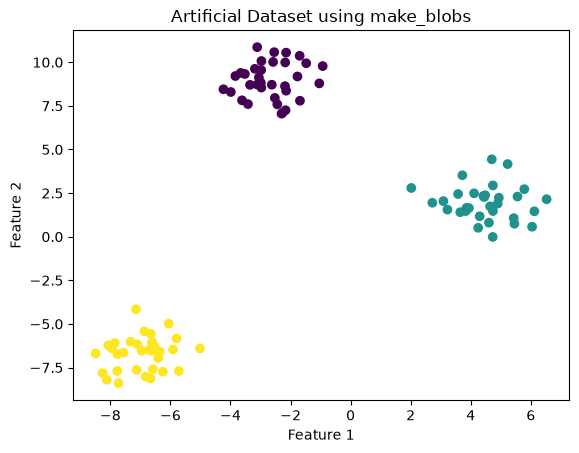

In [2]:
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt

# Daten erzeugen
X, y = make_blobs(
    n_samples=100, #100 Datenpunkte erzeugt
    centers=3, #3 Kategorien
    n_features=2, #jeder Punkt hat 2 Eigenschaften
    random_state=42 #reproduzierbare Ergebnisse
)

# Daten visualisieren
plt.scatter(X[:, 0], X[:, 1], c=y) #bei X [[1, 2], [6, 7], [3, 4]] bedeutet X[:, 0] z.B., dass man alle Datenpunkte nimmt, aber nur das erste Feature

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Artificial Dataset using make_blobs")

plt.show()

Wir erstellen jetzt das ML Modell mit sklearn. Zuerst wird das Modell erstellt und da es hier numerische Werte sind, wird ein Regressionsmodell verwendet. Vereinfacht passiert Folgendes beim Training:
1. Das Modell untersucht die Eingabedaten.
2. Es sucht nach mathematischen Zusammenhängen zwischen Features und Labels.
3. Es berechnet passende Modellparameter (Gewichte und Bias).
4. Es passt diese Parameter so an, dass die Klassenzuordnung möglichst gut funktioniert.

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Modell trainieren
model = LogisticRegression() #Regression verwendet. Hier wird nur das Modell erstellt, aber noch nicht trainiert!

model.fit(X, y) #Hier wird es schon trainiert. Und zwar mit den X_train = Eingabedaten und y_train Ausgabedaten

# Vorhersage
predictions = model.predict(X)

print("Accuracy:", accuracy_score(y, predictions))

Accuracy: 1.0


Jetzt anzeigen lassen, welche Datenpunkte welchen Klassen zugeordnet wurden. Hier gehe ich davon aus, dass negative Feature 1 und positive Feature 2 Cluster 0 zugeordnet werden. Positive Feature 1 und Feature 2 werden Cluster 1 zugeordnet. Negative Feature 1 und Feature 2 werden Cluster 2 zugeordnet.

In [ ]:
import pandas as pd

df = pd.DataFrame(X, columns=["Feature 1", "Feature 2"])

df["Cluster"] = y

print(df)

    Feature 1  Feature 2  Cluster
0   -7.726421  -8.394957        2
1    5.453396   0.742305        1
2   -2.978672   9.556846        0
3    6.042673   0.571319        1
4   -6.521840  -6.319325        2
..        ...        ...      ...
95  -3.186120   9.625962        0
96  -1.478198   9.945566        0
97   4.478593   2.377221        1
98  -5.796576  -5.826308        2
99  -3.348415   8.705074        0

[100 rows x 3 columns]


2. Jetzt machen wir dasselbe, bloß in Pytorch

In [ ]:
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split

# Daten erzeugen
X, y = make_blobs(
    n_samples=500,
    centers=3,
    n_features=2,
    random_state=42
)

# Trainings- und Testdaten aufteilen
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

NumPy Daten konvertieren

In [ ]:
import torch

# Features
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

# Labels
y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

Neuronales Netzwerk erstellen. Jeder Datenpunkt bekommt 2 Features mit nn.Linear(2, 16) gibt es 2 Features und 16 Neuronen. nn.ReLU() ist die Aktivierungsfunktion, sie setzt negative Werte auf 0 und lässt positive Werte unverändert. nn.Linear(16, 3) definiert 3 Ausgabewerte.

In [ ]:
import torch.nn as nn

# Neuronales Netzwerk erstellen
model = nn.Sequential( #hier wird das Netzwerk erstellt. statt regression in sklearn ist es hier sequential

    # Input Layer -> Hidden Layer
    nn.Linear(2, 16),

    # Aktivierungsfunktion
    nn.ReLU(),

    # Hidden Layer -> Output Layer
    nn.Linear(16, 3)
)

print(model)

Sequential(
  (0): Linear(in_features=2, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=3, bias=True)
)


Wie lernt das Netzwerk? Hier gibt es zwei wichtige Bestandteile:

A) Loss Function

CrossEntropyLoss() misst, wie stark die Vorhersagen des Netzwerks von den tatsächlichen Klassen abweichen.

Je kleiner der Loss, desto besser sind die Vorhersagen im Allgemeinen.

B) Optimizer

Adam verändert die Gewichte des neuronalen Netzwerks, um den Loss zu reduzieren.

lr=0.01 steht für Learning Rate. Sie bestimmt, wie groß die einzelnen Anpassungsschritte sind.

In [ ]:
# Loss-Funktion
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01
)

Jetzt das Modell trainieren. 
1	zero_grad()	Alte Gradienten löschen
2	model(X_train)	Vorhersagen berechnen
3	criterion(...)	Fehler berechnen
4	loss.backward()	Gradienten berechnen
5	optimizer.step()	Gewichte aktualisieren

Diese fünf Schritte werden 100-mal wiederholt.

Das nennt man Training über 100 Epochen.

Wichtig: Eine Epoche bedeutet hier, dass das gesamte Trainingsset einmal durch das Netzwerk verarbeitet wird.

In [ ]:
# Training
epochs = 100

for epoch in range(epochs):

    # 1. Alte Gradienten zurücksetzen
    optimizer.zero_grad()

    # 2. Vorhersage erstellen
    outputs = model(X_train)

    # 3. Loss berechnen
    loss = criterion(outputs, y_train)

    # 4. Backpropagation
    loss.backward()

    # 5. Gewichte aktualisieren
    optimizer.step()

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch+1}/{epochs}], "
            f"Loss: {loss.item():.4f}"
        )

Epoch [10/100], Loss: 0.0682
Epoch [20/100], Loss: 0.0113
Epoch [30/100], Loss: 0.0038
Epoch [40/100], Loss: 0.0022
Epoch [50/100], Loss: 0.0017
Epoch [60/100], Loss: 0.0014
Epoch [70/100], Loss: 0.0012
Epoch [80/100], Loss: 0.0011
Epoch [90/100], Loss: 0.0010
Epoch [100/100], Loss: 0.0009


Das Modell testen. Wir verwenden dafür unsere 100 Testdatenpunkte, die das Modell während des Trainings nicht gesehen hat.
model.eval() schaltet das Netzwerk in den Evaluierungsmodus.
1. torch.no_grad() deaktiviert die Gradientenberechnung, da wir nicht mehr trainieren.
2. model(X_test) berechnet die Vorhersagen.
3. torch.argmax(outputs, dim=1) wählt für jeden Datenpunkt die Klasse mit dem höchsten Ausgabewert.
4. Wir vergleichen die Vorhersagen mit den tatsächlichen Labels.

In [ ]:
# Modell in Evaluierungsmodus setzen
model.eval()

# Keine Gradienten beim Testen berechnen
with torch.no_grad():

    # Vorhersagen erstellen
    outputs = model(X_test)

    # Höchsten Score als vorhergesagte Klasse auswählen
    predictions = torch.argmax(outputs, dim=1)

    # Accuracy berechnen
    accuracy = (predictions == y_test).float().mean()

print("PyTorch Accuracy:", accuracy.item())

PyTorch Accuracy: 1.0


Datenpunkte visualisieren. und wie wurde klassifieziert?

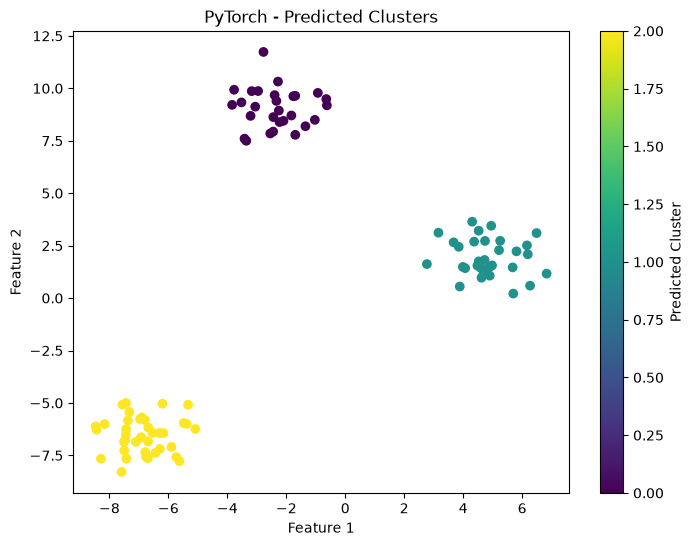

In [ ]:
import matplotlib.pyplot as plt

# Tensoren zurück in NumPy umwandeln
X_test_np = X_test.numpy()
predictions_np = predictions.numpy()

plt.figure(figsize=(8, 6))

plt.scatter(
    X_test_np[:, 0],
    X_test_np[:, 1],
    c=predictions_np,
    cmap="viridis"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("PyTorch - Predicted Clusters")

plt.colorbar(label="Predicted Cluster")
plt.show()

3. Einen MC Dropout erstellen. 

In [ ]:
from __future__ import annotations

from sklearn.datasets import make_moons
import torch
from torch import nn

from probly.representer import representer
from probly.transformation import dropout

from examples.utils.model import MLPClassifier
from examples.utils.plotting import plot_example_uncertainty

ModuleNotFoundError: No module named 'sklearn'

In [3]:
%pip install probly scikit-learn matplotlib numpy

/Users/juliareda/Documents/LMU/Semester3/SEP/Project/probly/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


/Users/juliareda/Documents/LMU/Semester3/SEP/Project/probly/.venv/bin/python: No module named uv
Note: you may need to restart the kernel to use updated packages.


In [1]:
import probly

print(probly.__version__)

ModuleNotFoundError: No module named 'probly'

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification, make_regression
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, mean_squared_error

In [1]:
from probly.method import ensemble
from probly.representer import representer
from probly.quantification import quantify

ModuleNotFoundError: No module named 'probly'

LogisticRegression_and_Probly_->für_das_benutzen_wir_Conformal_Prediction